In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

who = [
    "BIII_S1",
    "BIII_S2",
    "BIII_S3",
    "BIII_S4",
    "BIII_S5",
]

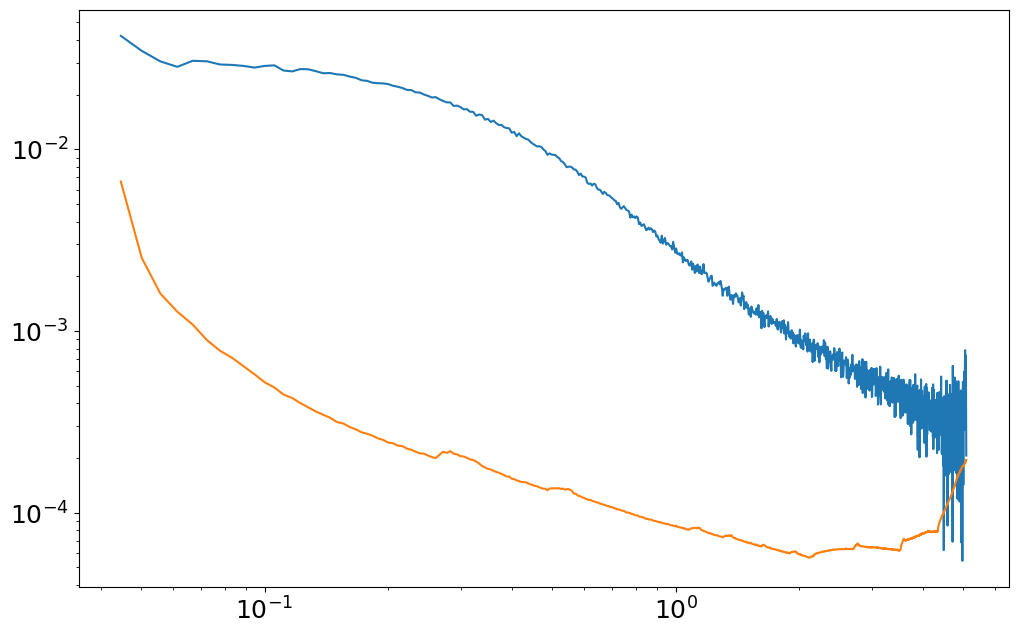

In [2]:
sample = "BIII_S5" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)
mask = (q <= 5.1) # & (q >= 0.045)
q    = q[mask]
I    = I[mask]
Ierr = Ierr[mask]

plt.figure(figsize=(12, 7.5))
plt.loglog(q, I)
plt.loglog(q, Ierr)

Guinier fit results for BIII_S5_100uM_aSynE46K:
I(0) = 0.0297 ± 0.00017
Rg   = 4.412 ± 0.039
Check: q_max * Rg = 1.324 (should be < 1.3 for Guinier approximation)


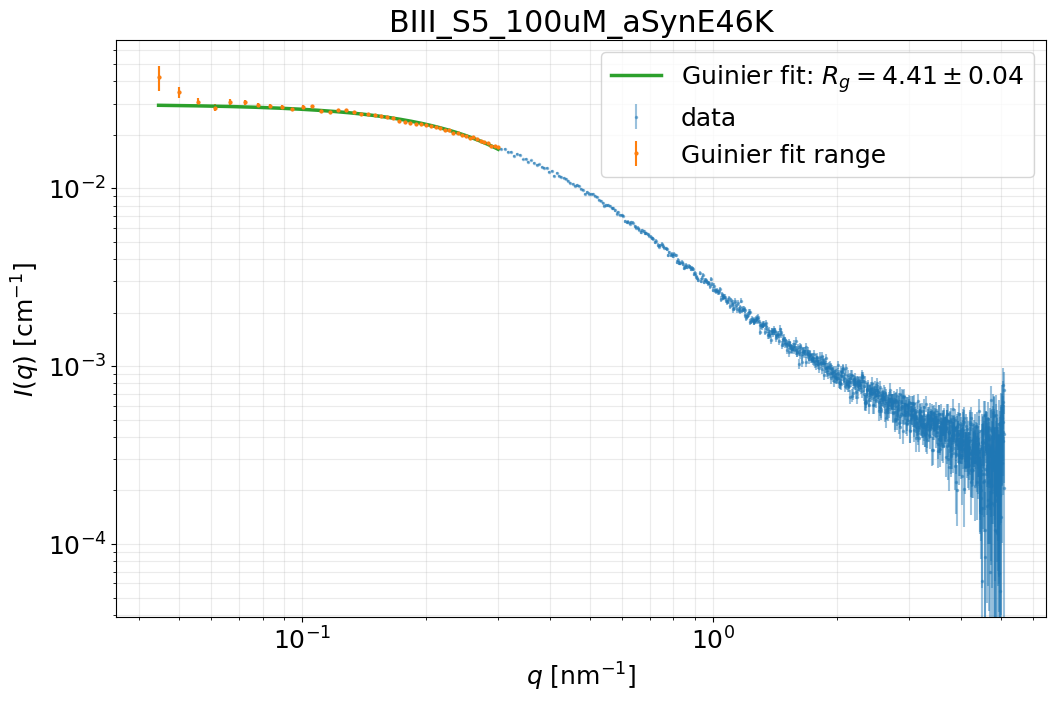

In [12]:
# Adjustable Guinier fit settings
q_min, q_max = 0.0, 0.3
initial_guess = [I[0], 4.0]  # [I0, Rg]
bounds = ([0.0, 0.0], [np.inf, np.inf])

fit_mask = (
    (q >= q_min)
    & (q <= q_max)
)

q_fit = q[fit_mask]
I_fit = I[fit_mask]
Ierr_fit = Ierr[fit_mask]

popt, pcov = optimize.curve_fit(
    fit.guinier_fit,
    q_fit,
    I_fit,
    p0=initial_guess,
    sigma=Ierr_fit,
    bounds=bounds,
    maxfev=10000,
)

I0, Rg = popt
I0_err, Rg_err = np.sqrt(np.diag(pcov))

q_plot = np.linspace(q_fit.min(), q_fit.max(), 500)
I_guinier = fit.guinier_fit(q_plot, *popt)

print(f"Guinier fit results for {BM29.sample_dict[sample]}:")
print(f"I(0) = {I0:.4g} ± {I0_err:.2g}")
print(f"Rg   = {Rg:.3f} ± {Rg_err:.3f}")
print(f"Check: q_max * Rg = {q_max * Rg:.3f} (should be < 1.3 for Guinier approximation)")

plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, yerr=Ierr, fmt=".", ms=3, alpha=0.45, label="data")
plt.errorbar(q_fit, I_fit, yerr=Ierr_fit, fmt=".", ms=4, label="Guinier fit range")
plt.plot(q_plot, I_guinier, lw=2.5, label=fr"Guinier fit: $R_g={Rg:.2f}\pm{Rg_err:.2f}$")

plt.yscale("log")
plt.xscale("log")
plt.xlabel(r"$q$ [nm$^{-1}$]")
plt.ylabel(r"$I(q)$ [cm$^{-1}$]")
plt.title(f"{BM29.sample_dict[sample]}")
plt.legend()
plt.grid(True, which="both", alpha=0.25)
plt.show()